In [38]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import warnings
warnings.filterwarnings('ignore')

import os, sys, re
from pathlib import Path
from ast import literal_eval
import numpy as np
# import json, pickle
from tqdm.auto import tqdm
from tqdm.contrib import tzip
from copy import deepcopy

import pandas as pd
from functools import reduce
# from itables import init_notebook_mode
# init_notebook_mode(all_interactive=True)

from rdkit import Chem
from rdkit.Chem import PandasTools
from rdkit.Chem import AllChem, rdDepictor
PandasTools.RenderImagesInAllDataFrames(images=True)
from rdkit import RDLogger; RDLogger.DisableLog('rdApp.*')

from rdkit.Chem.Draw import IPythonConsole
IPythonConsole.ipython_useSVG = True
IPythonConsole.molSize = 600, 400
# IPythonConsole.drawOptions.addAtomIndices = True

def reset_view(mol):
    """ Reset coordinates for display """
    mol = deepcopy(mol)
    rdDepictor.SetPreferCoordGen(True)
    rdDepictor.Compute2DCoords(mol)
    rdDepictor.StraightenDepiction(mol)
    return mol

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
database3 = pd.read_csv('data/Database3.csv')
PandasTools.AddMoleculeColumnToFrame(database3, 'ISOSMILES')
df_lipidmaps = pd.read_pickle('data/Database_lipidmaps.pkl')

# Cluster 

In [35]:
query_mol = reset_view(database3.at[1, 'ROMol'])

In [36]:
from new_geass import Geass

geass = Geass(query_mol)
final_prods = geass.get_fragments()
final_Prod = reduce(Chem.CombineMols, final_prods)
geass.show_connections_graph()

CytoscapeWidget(cytoscape_layout={'name': 'cose'}, cytoscape_style=[{'selector': 'node', 'css': {'content': 'd…

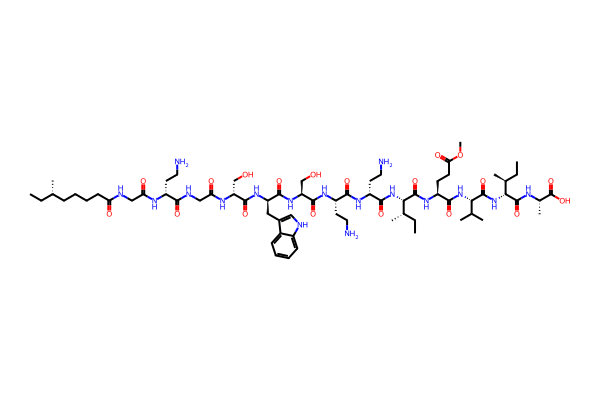

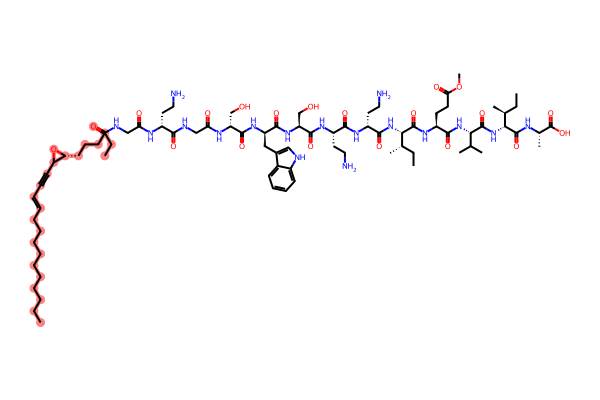

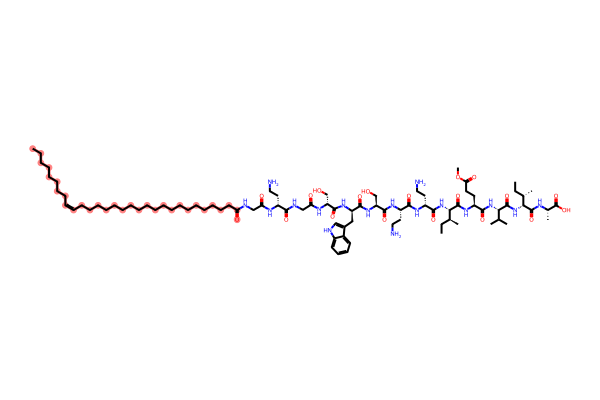

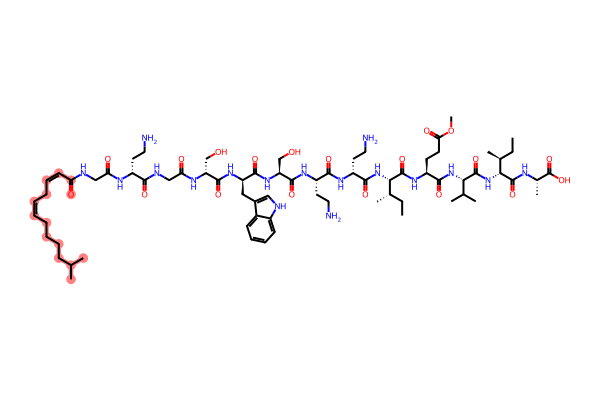

In [42]:
tail_to_replace = 'CC[C@H](C)CCCCC(=O)O'
tail_to_replace = Chem.MolFromSmiles(tail_to_replace.replace('C(=O)O', 'C(=O)'))
new_tails = df_lipidmaps[df_lipidmaps['ID'].str.contains('FA01')]['ISOSMILES'].sample(3).tolist()[:3]

chimeras = []
for new_tail in new_tails:
    # Skip if the pattern and replacement are the same
    if new_tail == tail_to_replace:
        continue

    new_tail = Chem.MolFromSmiles(new_tail.replace('C(=O)O', 'C(=O)'))

    # Renumber atoms for the pattern (atom 0 must be the one involved in bond breaking)
    acetyl_patt = tail_to_replace.GetSubstructMatch(Chem.MolFromSmiles('C(=O)C'))
    new_order_patt = list(acetyl_patt) + [x for x in range(tail_to_replace.GetNumAtoms()) if x not in acetyl_patt][::-1]
    new_patt = AllChem.RenumberAtoms(tail_to_replace, new_order_patt)

    # Renumber atoms for the replacement
    acetyl_repl = new_tail.GetSubstructMatch(Chem.MolFromSmiles('C(=O)C'))
    new_order_repl = list(acetyl_repl) + [x for x in range(new_tail.GetNumAtoms()) if x not in acetyl_repl][::-1]
    new_repl = AllChem.RenumberAtoms(new_tail, new_order_repl)

    # Replace the substructure in the original molecule
    chimera = AllChem.ReplaceSubstructs(query_mol, new_patt, new_repl)
    chimera[0].GetSubstructMatches(new_repl)

    chimeras.append(reset_view(chimera[0]))
display(query_mol, *chimeras)

In [16]:
df_chimeras = pd.DataFrame({'ISOSMILES': [Chem.MolToSmiles(x) for x in chimeras]})
df_chimeras.to_csv(f"{workdir}/DeliverableMarta/chimeras.csv", index=False)